# Task-Aware Importance Sampling: Independent VAE Confirmation Study

**Colab-ready experiment** — based on the *Task-Aware Amortized Importance Sampling* research report (Section 6), extending the inconclusive three-seed VAE pilot into a controlled, repeated experiment.

**Primary question:** Under the **same total online sample budget**, does amortized allocation based on estimated posterior-mean variance reduce posterior-mean error compared with uniform allocation for a **learned VAE**?

### Study protocol (fixed before looking at results)

- **Data:** `sklearn.datasets.load_digits`, real handwritten digits, grayscale **8 × 8**, values scaled to [0,1]. This is **not** 28 × 28 MNIST.
- **Generative model:** independently trained Gaussian-likelihood VAEs with **4 latent dimensions** and 25 model-training seeds. Each VAE has its own independently fitted task-aware and ESS-based offline predictors. A shared, frozen stratified train/validation/test split avoids leakage. Optional secondary experiment: 8 latent dimensions.
- **Methods:** Uniform (primary control), TaskAware (primary treatment), ESSBased (secondary baseline), and ShuffledTask (negative control). All receive exactly **48 samples per observation on average** in **groups of 64**, with individual allocation bounds **4–120**.
- **Teacher data:** 800 development observations, **512 offline samples per observation**, separately for each training seed. No test images or high-budget references are used to train the predictors or choose allocations.
- **Target quantity:** posterior mean of latent variables, estimated by **self-normalized importance sampling (SNIS)**. Teacher targets estimate the asymptotic per-observation variance relevant to this quantity; ESS teacher targets depend only on weights.
- **Reference:** two **independent** high-budget SNIS runs of 16,384 proposal draws each per held-out image; the two pools are combined by their weight sums into a **32,768-draw** reference. We report reference-to-reference disagreement and reference effective sample fraction. This is an **estimate, not a ground-truth posterior mean**.
- **Testing:** 256 held-out test images (4 groups × 64), 12 paired online Monte Carlo repeats per VAE. Common random proposal draws are used across methods within each repeat.
- **Primary inferential unit:** **independent VAE training seed**, not each repeated draw/image. Analyze paired seed-level MSE differences with a 95% Student-t interval, seed-level sign-flip permutation test, and bootstrap confidence interval for percentage reduction. These conclusions concern a **fixed data split and this VAE architecture**.
- **Secondary outcome:** absolute log-evidence error compared against the independent high-budget SNIS reference, clearly labeled an approximate diagnostic, not a comparison to exact evidence.

**Interpretation:** A numerically lower error does *not* imply a scientifically supported improvement. If reference disagreement is appreciable, confidence intervals include zero, or the VAE proposal has degenerate weights, report the result as limited/inconclusive. The results are not known in advance, and the notebook never inserts fabricated findings.

**Reproducibility note:** This is a *new, transparent extension* built from the report's stated experiment; because the original implementation notebook/checkpoints were not supplied, it is **not an exact code-level reproduction** of the original three-seed run.

## 1 · Runtime, persistence, and settings

In Colab select **Runtime → Change runtime type → GPU**. Run cells **in order**. For long runs, set `USE_GOOGLE_DRIVE=True` to save seed-by-seed results in Drive; rerunning the same configuration skips completed seeds. `RUN_MODE="smoke"` tests the full pipeline quickly **but its output is not valid for SOP claims**. Leave `RUN_MODE="full"` for research results.

In [1]:
import os, sys, json, math, random, time, hashlib, platform
from pathlib import Path
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
import torch
from torch import nn
from torch.nn import functional as F
from tqdm.auto import tqdm
from IPython.display import display

# RESEARCH settings: do not change after inspecting final results.
RUN_MODE = "full"           # "full" or "smoke" (for debugging only)
USE_GOOGLE_DRIVE = False    # set True for persistent Colab checkpoints
RUN_8D_SECONDARY = True    # True runs 8D as an additional, exploratory architecture

@dataclass(frozen=True)
class Config:
    latent_dims: tuple = (4,)
    n_seeds: int = 25
    epochs: int = 65
    batch_size: int = 128
    hidden: int = 128
    decoder_sigma: float = 0.15
    learning_rate: float = 1e-3
    k_teacher: int = 512
    n_dev: int = 800
    n_predictor_validation: int = 128
    n_test: int = 256
    group_size: int = 64
    k_average: int = 48
    k_min: int = 4
    k_max: int = 120
    online_repeats: int = 12
    n_reference_each: int = 16_384
    reference_chunk: int = 2_048
    reference_image_batch: int = 16
    seed_start: int = 27_000
    split_seed: int = 2_026
    bootstrap_repeats: int = 10_000
    signflip_repeats: int = 100_000

if RUN_MODE == "full":
    cfg = Config(latent_dims=(4, 8) if RUN_8D_SECONDARY else (4,))
elif RUN_MODE == "smoke":
    cfg = Config(n_seeds=2, epochs=2, n_dev=96,
                 n_predictor_validation=32, n_test=64,
                 online_repeats=2, n_reference_each=256,
                 reference_chunk=128, reference_image_batch=16,
                 bootstrap_repeats=200, signflip_repeats=200)
else:
    raise ValueError('RUN_MODE must be "full" or "smoke"')

assert cfg.n_test % cfg.group_size == 0
assert cfg.k_min <= cfg.k_average <= cfg.k_max
assert cfg.n_dev <= 1000 and cfg.n_reference_each % cfg.reference_chunk == 0

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        root = Path('/content/drive/MyDrive/TaskAware_VAE_Confirmation')
    except ImportError:
        raise RuntimeError('Google Drive mounting is available in Google Colab only.')
else:
    root = Path('/content/TaskAware_VAE_Confirmation') if 'google.colab' in sys.modules else Path('TaskAware_VAE_Confirmation')

run_hash = hashlib.sha256(json.dumps(asdict(cfg), sort_keys=True).encode()).hexdigest()[:12]
OUT = root / f'{RUN_MODE}_{run_hash}'
OUT.mkdir(parents=True, exist_ok=True)
(OUT/'config.json').write_text(json.dumps({'mode':RUN_MODE, **asdict(cfg)}, indent=2))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
print('Torch:', torch.__version__, 'Sklearn:', sklearn.__version__)
print('Results:', OUT.resolve())
print('Configuration:', asdict(cfg))
if DEVICE.type != 'cuda':
    print('WARNING: no CUDA GPU detected. The full experiment may be slow.')
if RUN_MODE == 'smoke':
    print('SMOKE TEST ONLY — not enough data for an SOP claim.')

Device: cpu
Torch: 2.14.1+cpu Sklearn: 1.6.1
Results: /content/TaskAware_VAE_Confirmation/full_86f150f51f1b
Configuration: {'latent_dims': (4, 8), 'n_seeds': 25, 'epochs': 65, 'batch_size': 128, 'hidden': 128, 'decoder_sigma': 0.15, 'learning_rate': 0.001, 'k_teacher': 512, 'n_dev': 800, 'n_predictor_validation': 128, 'n_test': 256, 'group_size': 64, 'k_average': 48, 'k_min': 4, 'k_max': 120, 'online_repeats': 12, 'n_reference_each': 16384, 'reference_chunk': 2048, 'reference_image_batch': 16, 'seed_start': 27000, 'split_seed': 2026, 'bootstrap_repeats': 10000, 'signflip_repeats': 100000}


## 2 · Frozen, disjoint data partitions

Train and fit the VAE on the training split. Train the offline allocation predictors on **800 training images**. Use validation images only for a predictor diagnostic, never for final allocation fitting or model selection. All four allocation methods use the same unseen 256-image test set and the same seeds. The digit split is fixed across the 25 VAE training seeds; this distinguishes *variation across training runs* from *variation across datasets*.

In [2]:
def fix_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def torch_rng(seed):
    g = torch.Generator(device=DEVICE.type)
    g.manual_seed(int(seed))
    return g

all_x, all_y = load_digits(return_X_y=True)
all_x = (all_x.astype(np.float32) / 16.0)
all_y = all_y.astype(int)
indices = np.arange(len(all_x))
train_val_idx, test_idx = train_test_split(
    indices, test_size=0.20, random_state=cfg.split_seed, stratify=all_y)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.20, random_state=cfg.split_seed+1,
    stratify=all_y[train_val_idx])
select_test, _ = train_test_split(
    test_idx, train_size=cfg.n_test,
    random_state=cfg.split_seed+2, stratify=all_y[test_idx])
rng_partition = np.random.default_rng(cfg.split_seed+3)
select_dev = rng_partition.choice(train_idx, cfg.n_dev, replace=False)
select_val = rng_partition.choice(val_idx, cfg.n_predictor_validation, replace=False)

x_train = torch.as_tensor(all_x[train_idx], dtype=torch.float32)
x_dev = torch.as_tensor(all_x[select_dev], dtype=torch.float32)
x_valid = torch.as_tensor(all_x[select_val], dtype=torch.float32)
x_test = torch.as_tensor(all_x[select_test], dtype=torch.float32)
assert set(train_idx).isdisjoint(test_idx) and set(train_idx).isdisjoint(val_idx)
assert set(val_idx).isdisjoint(test_idx)
assert len(x_test)==cfg.n_test and len(x_dev)==cfg.n_dev
print('Train:', len(train_idx), 'Validation:',len(val_idx), 'Test:',len(test_idx))
print('Predictor development:',len(x_dev),'Validation diagnostic:',len(x_valid), 'Final test:',len(x_test))
print('Test digit distribution:',np.bincount(all_y[select_test],minlength=10))

Train: 1149 Validation: 288 Test: 360
Predictor development: 800 Validation diagnostic: 128 Final test: 256
Test digit distribution: [26 26 25 26 26 26 25 26 25 25]


## 3 · Explicit probabilistic model and training

The VAE uses a standard normal prior `p(z)=N(0,I)`, diagonal-Gaussian encoder `qφ(z|x)`, and **fixed-variance Gaussian decoder** `pθ(x|z)=N(decoderθ(z), 0.15²I)`. This is suitable for continuously valued grayscale pixels. The negative-ELBO training loss has reconstruction term `||x - decoder(z)||² / (2 σ²)` plus analytic Gaussian KL, with constants independent of model parameters omitted.

All methods compare inference under the *same* trained VAE and encoder proposal. The 25 VAE runs are independent initializations/training randomness on the same frozen split. The result concerns this specific architecture and decoder likelihood.

In [3]:
LOG2PI = float(np.log(2.0 * np.pi))
class GaussianVAE(nn.Module):
    def __init__(self, latent_dim, hidden=128, decoder_sigma=0.15):
        super().__init__()
        self.latent_dim = latent_dim
        self.decoder_sigma = float(decoder_sigma)
        self.encoder = nn.Sequential(nn.Linear(64,hidden), nn.ReLU(),
                                     nn.Linear(hidden,hidden), nn.ReLU())
        self.fc_mu = nn.Linear(hidden,latent_dim)
        self.fc_lv = nn.Linear(hidden,latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim,hidden),nn.ReLU(),
                                     nn.Linear(hidden,hidden),nn.ReLU(),
                                     nn.Linear(hidden,64),nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_lv(h).clamp(-10., 6.)

    def forward(self, x):
        mu, lv = self.encode(x)
        z = mu + torch.exp(0.5*lv) * torch.randn_like(mu)
        return self.decoder(z), mu, lv

def train_vae(model, xtrain, seed):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=cfg.learning_rate)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(xtrain),
        batch_size=cfg.batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed))
    hist=[]
    for epoch in range(cfg.epochs):
        total=0.0
        for (xb_cpu,) in loader:
            xb=xb_cpu.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            recon,mu,lv = model(xb)
            rec=((xb-recon)**2).sum(1)/(2*model.decoder_sigma**2)
            kl=-0.5*torch.sum(1+lv-mu.square()-lv.exp(),dim=1)
            loss=(rec+kl).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError('VAE loss became non-finite')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),5.0)
            opt.step()
            total+=float(loss.detach())*len(xb)
        hist.append({'seed':seed,'epoch':epoch+1,'negative_elbo_without_const':total/len(xtrain)})
    model.eval()
    return pd.DataFrame(hist)

@torch.inference_mode()
def get_features(model, xs, batch=128):
    blocks=[]
    for begin in range(0,len(xs),batch):
        x=xs[begin:begin+batch].to(DEVICE)
        mu,lv=model.encode(x)
        qstd=torch.exp(0.5*lv)
        rec=model.decoder(mu)
        kl=-0.5*(1+lv-mu.square()-lv.exp()).sum(dim=1,keepdim=True)
        features=torch.cat([
            x,x.square(),torch.linalg.vector_norm(x,dim=1,keepdim=True),
            torch.linalg.vector_norm(mu,dim=1,keepdim=True),
            qstd.mean(dim=1,keepdim=True),qstd.max(dim=1,keepdim=True).values,
            ((x-rec)**2).mean(dim=1,keepdim=True),kl,
            torch.full((len(x),1),model.decoder_sigma,device=DEVICE)
        ],dim=1)
        blocks.append(features.cpu().numpy())
    return np.concatenate(blocks).astype(np.float32)

@torch.inference_mode()
def draw_logweights(model, xb, count, generator):
    """Return z[n,K,d], log p(z)+log p(x|z)-log q(z|x)[n,K]."""
    xb=xb.to(DEVICE)
    mu,lv=model.encode(xb)
    std=torch.exp(0.5*lv)
    z=mu[:,None,:] + std[:,None,:]*torch.randn(
        (len(xb),int(count),model.latent_dim),device=DEVICE,generator=generator)
    recon=model.decoder(z.reshape(-1,model.latent_dim)).reshape(len(xb),count,64)
    log_pz=-0.5*(z.square()+LOG2PI).sum(dim=-1)
    log_q=-0.5*(((z-mu[:,None,:])/std[:,None,:]).square()
                  +lv[:,None,:]+LOG2PI).sum(dim=-1)
    log_px=-0.5*((xb[:,None,:]-recon).square()/model.decoder_sigma**2
                 +2*math.log(model.decoder_sigma)+LOG2PI).sum(dim=-1)
    lw=log_px+log_pz-log_q
    if not torch.isfinite(lw).all():
        raise FloatingPointError('Non-finite importance weight')
    return z,lw

## 4 · Train **matched** offline allocation predictors

For each development observation, use the same teacher draws to construct both targets:

\[\widehat{\tau^2}_i=K_{dev}\sum_k \widetilde{w}_{ik}^2\|z_{ik}-\widehat\mu_i\|^2,\qquad
\widehat{\operatorname{ESS}}_i=\left(\sum_k\widetilde{w}_{ik}^2\right)^{-1}.\]

The task score is `sqrt(max(tau², 1e-5)) + 0.02`; ESS score is `sqrt(max(Kdev/ESS - 1,0)) + 0.05`, following the report's stabilized teacher score idea. Train two identical `HistGradientBoostingRegressor` architectures on the **log scores**. Predicted scores use no online pilot calls. The held-out predictor-validation diagnostic is reported, **not used to adjust final methods**.

In [4]:
@torch.inference_mode()
def teacher_scores(model, xs, seed):
    g=torch_rng(seed)
    task_scores=[]; ess_scores=[]
    for begin in range(0,len(xs),32):
        z,lw=draw_logweights(model,xs[begin:begin+32],cfg.k_teacher,g)
        weights=torch.softmax(lw,dim=1)
        m=(weights[:,:,None]*z).sum(dim=1)
        tau2=cfg.k_teacher*(weights.square()*(z-m[:,None,:]).square().sum(dim=-1)).sum(dim=1)
        ess=1.0/weights.square().sum(dim=1)
        task=torch.sqrt(tau2.clamp_min(1e-5))+0.02
        essscore=torch.sqrt((cfg.k_teacher/ess-1.).clamp_min(0.))+0.05
        task_scores.extend(task.cpu().numpy().tolist())
        ess_scores.extend(essscore.cpu().numpy().tolist())
    return np.asarray(task_scores),np.asarray(ess_scores)

def fit_predictors(model, dim, seed):
    feat=get_features(model,x_dev)
    score_task,score_ess=teacher_scores(model,x_dev,seed+1_100_000)
    params=dict(max_iter=130,max_leaf_nodes=10,l2_regularization=2.0,
                min_samples_leaf=20,random_state=seed)
    task_reg=HistGradientBoostingRegressor(**params).fit(feat,np.log(score_task))
    ess_reg=HistGradientBoostingRegressor(**params).fit(feat,np.log(score_ess))
    val_feat=get_features(model,x_valid)
    val_task,val_ess=teacher_scores(model,x_valid,seed+1_200_000)
    pred_task_val=np.exp(task_reg.predict(val_feat))
    pred_ess_val=np.exp(ess_reg.predict(val_feat))
    rho_task=stats.spearmanr(pred_task_val,val_task).statistic
    rho_ess=stats.spearmanr(pred_ess_val,val_ess).statistic
    feat_test=get_features(model,x_test)
    pred_task=np.exp(task_reg.predict(feat_test)).clip(1e-6,1e6)
    pred_ess=np.exp(ess_reg.predict(feat_test)).clip(1e-6,1e6)
    return pred_task,pred_ess,{
        'latent_dim':dim,'seed':seed,
        'task_teacher_vs_pred_spearman_val':float(rho_task),
        'ess_teacher_vs_pred_spearman_val':float(rho_ess),
        'teacher_budget':cfg.k_teacher,'n_dev':cfg.n_dev,
        'val_task_score_std':float(np.std(val_task))}

## 5 · Reference posterior expectations, independent replications, and ESS

This is the largest GPU step. Streaming log-weight sums keep memory bounded. Two disjoint random-number streams give `ref_A` and `ref_B`. We combine the pools using their summed importance weights, not a simple average of their posterior means. **Neither independent high-budget run is exact ground truth.** Their disagreement and combined ESS/sample ratio are diagnostics of how trustworthy this estimated reference is.

In [5]:
@torch.inference_mode()
def reference_pass(model, xs, seed):
    ref_mu=[];ref_logz=[];ref_ess=[]
    g=torch_rng(seed)
    for begin in range(0,len(xs),cfg.reference_image_batch):
        xb=xs[begin:begin+cfg.reference_image_batch]
        n=len(xb);d=model.latent_dim
        # Accumulate sums after multiplying by exp(-max log-weight).
        maxlog=torch.full((n,),-float('inf'),device=DEVICE,dtype=torch.float64)
        sumw=torch.zeros(n,device=DEVICE,dtype=torch.float64)
        sumwz=torch.zeros((n,d),device=DEVICE,dtype=torch.float64)
        sumw2=torch.zeros(n,device=DEVICE,dtype=torch.float64)
        for _ in range(0,cfg.n_reference_each,cfg.reference_chunk):
            z,lw=draw_logweights(model,xb,cfg.reference_chunk,g)
            lw=lw.double(); z=z.double()
            new_max=torch.maximum(maxlog,lw.max(dim=1).values)
            oldscale=torch.exp(maxlog-new_max)
            neww=torch.exp(lw-new_max[:,None])
            sumw=sumw*oldscale+neww.sum(dim=1)
            sumwz=sumwz*oldscale[:,None]+(neww[:,:,None]*z).sum(dim=1)
            sumw2=sumw2*oldscale.square()+neww.square().sum(dim=1)
            maxlog=new_max
        mu=sumwz/sumw[:,None]
        lz=maxlog+sumw.log()-math.log(cfg.n_reference_each)
        ess=sumw.square()/sumw2
        ref_mu.append(mu.cpu().numpy())
        ref_logz.append(lz.cpu().numpy())
        ref_ess.append(ess.cpu().numpy())
    return (np.concatenate(ref_mu),np.concatenate(ref_logz),np.concatenate(ref_ess))

def make_references(model,dim,seed):
    a,za,essa=reference_pass(model,x_test,seed+2_100_000)
    b,zb,essb=reference_pass(model,x_test,seed+2_200_000)
    lsum=np.logaddexp(za,zb)
    pa=np.exp(za-lsum)
    pb=np.exp(zb-lsum)
    mu=pa[:,None]*a+pb[:,None]*b
    logz=lsum-math.log(2.0)
    ess_comb=1.0/(pa**2/essa + pb**2/essb)
    reference_disagreement=((a-b)**2).mean(axis=1)
    diag={
        'latent_dim':dim,'seed':seed,
        'reference_pair_mse':float(reference_disagreement.mean()),
        'reference_pair_logz_mae':float(np.mean(np.abs(za-zb))),
        'reference_ess_fraction_median':float(np.median(ess_comb/(2*cfg.n_reference_each))),
        'reference_ess_fraction_p05':float(np.percentile(ess_comb/(2*cfg.n_reference_each),5)),
        'reference_ess_fraction_below_1pct':float(np.mean(ess_comb/(2*cfg.n_reference_each)<0.01))}
    return {'mu':mu,'logz':logz,'a':a,'b':b,'za':za,'zb':zb},diag

## 6 · Capped sample allocation with exact group budgets

The unconstrained optimal asymptotic allocation to minimize a sum of per-observation posterior-mean variances is proportional to `sqrt(tau²)`. We impose `4 ≤ Kᵢ ≤ 120`, a total of `64 × 48 = 3072` per group, and integer allocations. `ESSBased` applies the same allocation mechanism to the separate ESS-derived difficulty score. `ShuffledTask` preserves the distribution of task scores while removing their correspondence to images.

In [6]:
def bounded_allocate(scores,budget,kmin,kmax):
    score=np.asarray(scores,dtype=float)
    if len(score)==0 or not np.isfinite(score).all() or (score<=0).any():
        raise ValueError('Allocation scores must be finite, positive and non-empty')
    n=len(score)
    if not(n*kmin <= budget <= n*kmax):
        raise ValueError('Budget infeasible')
    extra=int(budget-n*kmin)
    cap=int(kmax-kmin)
    if extra==0:return np.full(n,kmin,dtype=int)
    if extra==n*cap:return np.full(n,kmax,dtype=int)
    lo=0.0;hi=1.0
    # Find a Lagrange multiplier for capped proportional extras.
    while np.minimum(hi*score,cap).sum()<extra:
        hi*=2.0
    for _ in range(70):
        mid=(lo+hi)*0.5
        if np.minimum(mid*score,cap).sum()<extra:
            lo=mid
        else:
            hi=mid
    fractional=np.minimum(hi*score,cap)
    rounded=np.floor(fractional+1e-10).astype(int)
    remaining=int(extra-rounded.sum())
    if remaining>0:
        eligibility=np.flatnonzero(rounded<cap)
        order=eligibility[np.argsort(-(fractional[eligibility]-rounded[eligibility]),kind='stable')]
        assert remaining<=len(order)
        rounded[order[:remaining]]+=1
    out=rounded+kmin
    assert np.sum(out)==budget and out.min()>=kmin and out.max()<=kmax
    return out

def make_allocations(pred_task,pred_ess,seed):
    result={n:np.zeros(len(x_test),dtype=int) for n in
            ('Uniform','TaskAware','ESSBased','ShuffledTask')}
    budget=cfg.group_size*cfg.k_average
    for gi,start in enumerate(range(0,len(x_test),cfg.group_size)):
        idx=slice(start,start+cfg.group_size)
        p_task=pred_task[idx]
        p_ess=pred_ess[idx]
        shuf=np.random.default_rng(seed+gi+3_000_000).permutation(p_task)
        result['Uniform'][idx]=bounded_allocate(np.ones_like(p_task),budget,cfg.k_min,cfg.k_max)
        result['TaskAware'][idx]=bounded_allocate(p_task,budget,cfg.k_min,cfg.k_max)
        result['ESSBased'][idx]=bounded_allocate(p_ess,budget,cfg.k_min,cfg.k_max)
        result['ShuffledTask'][idx]=bounded_allocate(shuf,budget,cfg.k_min,cfg.k_max)
    for name,ki in result.items():
        assert np.all(ki>=cfg.k_min) and np.all(ki<=cfg.k_max)
        assert np.mean(ki)==cfg.k_average
        for j in range(0,len(ki),cfg.group_size):
            assert ki[j:j+cfg.group_size].sum()==budget
    return result

## 7 · Paired evaluation and diagnostics

Each seed gets its **own** trained VAE and its **own** offline predictors. For every online repeat, all methods reuse a single bank of 120 proposal draws per image and take the first `Kᵢ` draws indicated by their allocation. This uses common random numbers across methods, making paired comparisons less noisy. It does **not** give any method more than its allocated online queries.

In [7]:
@torch.inference_mode()
def evaluate_online(model,refs,allocations,dim,seed):
    records=[]
    counts={name:torch.as_tensor(values,device=DEVICE,dtype=torch.long)
            for name,values in allocations.items()}
    muc=torch.as_tensor(refs['mu'],device=DEVICE,dtype=torch.float64)
    mua=torch.as_tensor(refs['a'],device=DEVICE,dtype=torch.float64)
    mub=torch.as_tensor(refs['b'],device=DEVICE,dtype=torch.float64)
    lzc=torch.as_tensor(refs['logz'],device=DEVICE,dtype=torch.float64)
    lza=torch.as_tensor(refs['za'],device=DEVICE,dtype=torch.float64)
    lzb=torch.as_tensor(refs['zb'],device=DEVICE,dtype=torch.float64)
    arange_k=torch.arange(cfg.k_max,device=DEVICE)
    for rep in range(cfg.online_repeats):
        g=torch_rng(seed+4_000_000+rep)
        # test set fits in GPU: 256 x 120 x 4 (plus decoder activations)
        z,lw=draw_logweights(model,x_test,cfg.k_max,g)
        z=z.double();lw=lw.double()
        for name,ki in counts.items():
            mask=arange_k[None,:]<ki[:,None]
            masked_lw=lw.masked_fill(~mask,-float('inf'))
            weight=torch.softmax(masked_lw,dim=1)
            mu_hat=(weight[:,:,None]*z).sum(dim=1)
            logz_hat=torch.logsumexp(masked_lw,dim=1)-ki.double().log()
            rec={
                'latent_dim':dim,'seed':seed,'rep':rep,'method':name,
                'mse':float((mu_hat-muc).square().mean()),
                'mse_ref_A':float((mu_hat-mua).square().mean()),
                'mse_ref_B':float((mu_hat-mub).square().mean()),
                'logz_abs_error_ref':float((logz_hat-lzc).abs().mean()),
                'logz_abs_error_ref_A':float((logz_hat-lza).abs().mean()),
                'logz_abs_error_ref_B':float((logz_hat-lzb).abs().mean()),
                'mean_samples':float(ki.float().mean())}
            records.append(rec)
    allocation_rows=[]
    for name,arr in allocations.items():
        allocation_rows.append({'latent_dim':dim,'seed':seed,'method':name,
            'min_samples':int(arr.min()),'max_samples':int(arr.max()),
            'mean_samples':float(arr.mean()),'std_samples':float(arr.std()),
            'fraction_at_min':float((arr==cfg.k_min).mean()),
            'fraction_at_max':float((arr==cfg.k_max).mean())})
    return pd.DataFrame(records),pd.DataFrame(allocation_rows)

## 8 · Run, checkpoint, and resume

**One seed = one independently trained VAE and one complete evaluation.** After every seed, the notebook writes CSV and JSON files. If Colab disconnects, reopen the notebook with identical settings and rerun: it will skip completed seed files automatically. Never combine `smoke` outputs with the full study.

In [8]:
versions={
    'python':sys.version, 'torch':torch.__version__, 'sklearn':sklearn.__version__,
    'numpy':np.__version__, 'scipy':scipy.__version__,
    'device':str(DEVICE), 'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'platform':platform.platform()}
(OUT/'versions.json').write_text(json.dumps(versions,indent=2))

for dim in cfg.latent_dims:
    for i in tqdm(range(cfg.n_seeds),desc=f'VAE d={dim}'):
        seed=cfg.seed_start+i
        prefix=OUT/f'd{dim}_s{seed}'
        finished=prefix.with_suffix('.complete.json')
        if finished.exists():
            # Complete JSON is written last, only after all result files.
            print('Reusing completed seed:',dim,seed)
            continue
        fix_seed(seed)
        clock=time.time()
        model=GaussianVAE(dim,cfg.hidden,cfg.decoder_sigma).to(DEVICE)
        history=train_vae(model,x_train,seed)
        pred_task,pred_ess,pred_diag=fit_predictors(model,dim,seed)
        refs,ref_diag=make_references(model,dim,seed)
        allocations=make_allocations(pred_task,pred_ess,seed)
        metrics,allocation_diag=evaluate_online(model,refs,allocations,dim,seed)
        assert np.isfinite(metrics.select_dtypes('number').to_numpy()).all()
        history.to_csv(str(prefix)+'.training.csv',index=False)
        metrics.to_csv(str(prefix)+'.metrics.csv',index=False)
        allocation_diag.to_csv(str(prefix)+'.allocations.csv',index=False)
        pd.DataFrame([pred_diag]).to_csv(str(prefix)+'.predictor.csv',index=False)
        pd.DataFrame([ref_diag]).to_csv(str(prefix)+'.reference.csv',index=False)
        np.savez_compressed(str(prefix)+'.reference_arrays.npz',
            mu=refs['mu'],mu_a=refs['a'],mu_b=refs['b'],
            logz=refs['logz'],logz_a=refs['za'],logz_b=refs['zb'])
        summary={'latent_dim':dim,'seed':seed,'seconds':time.time()-clock,
                 'n_test':len(x_test),'n_repeats':cfg.online_repeats}
        finished.write_text(json.dumps(summary,indent=2))
        print(f'd={dim} seed={seed} done; {summary["seconds"]:.1f} sec; '
              f'ref pair MSE={ref_diag["reference_pair_mse"]:.6g}')
        del model
        if torch.cuda.is_available():torch.cuda.empty_cache()

print('Completed seed files:',len(list(OUT.glob('*.complete.json'))),
      '/',cfg.n_seeds*len(cfg.latent_dims))

VAE d=4:   0%|          | 0/25 [00:00<?, ?it/s]

d=4 seed=27000 done; 42.9 sec; ref pair MSE=0.00280336
d=4 seed=27001 done; 32.7 sec; ref pair MSE=0.00246932
d=4 seed=27002 done; 31.7 sec; ref pair MSE=0.00228024
d=4 seed=27003 done; 32.4 sec; ref pair MSE=0.00501089
d=4 seed=27004 done; 31.9 sec; ref pair MSE=0.00357545
d=4 seed=27005 done; 33.2 sec; ref pair MSE=0.00332953
d=4 seed=27006 done; 32.0 sec; ref pair MSE=0.00196312
d=4 seed=27007 done; 32.2 sec; ref pair MSE=0.00479585
d=4 seed=27008 done; 32.2 sec; ref pair MSE=0.00288655
d=4 seed=27009 done; 31.9 sec; ref pair MSE=0.00338533
d=4 seed=27010 done; 33.1 sec; ref pair MSE=0.00318362
d=4 seed=27011 done; 32.1 sec; ref pair MSE=0.00284584
d=4 seed=27012 done; 33.0 sec; ref pair MSE=0.00283369
d=4 seed=27013 done; 32.3 sec; ref pair MSE=0.00297747
d=4 seed=27014 done; 32.0 sec; ref pair MSE=0.00342167
d=4 seed=27015 done; 33.0 sec; ref pair MSE=0.00325027
d=4 seed=27016 done; 31.9 sec; ref pair MSE=0.00230843
d=4 seed=27017 done; 32.4 sec; ref pair MSE=0.00814344
d=4 seed=2

VAE d=8:   0%|          | 0/25 [00:00<?, ?it/s]

d=8 seed=27000 done; 33.3 sec; ref pair MSE=0.0284194
d=8 seed=27001 done; 32.3 sec; ref pair MSE=0.0232884
d=8 seed=27002 done; 33.3 sec; ref pair MSE=0.0311545
d=8 seed=27003 done; 32.3 sec; ref pair MSE=0.028207
d=8 seed=27004 done; 33.2 sec; ref pair MSE=0.0356403
d=8 seed=27005 done; 33.3 sec; ref pair MSE=0.0236149
d=8 seed=27006 done; 32.8 sec; ref pair MSE=0.027371
d=8 seed=27007 done; 33.7 sec; ref pair MSE=0.0240778
d=8 seed=27008 done; 32.4 sec; ref pair MSE=0.0233916
d=8 seed=27009 done; 33.8 sec; ref pair MSE=0.029337
d=8 seed=27010 done; 32.3 sec; ref pair MSE=0.0379363
d=8 seed=27011 done; 33.6 sec; ref pair MSE=0.0244599
d=8 seed=27012 done; 32.4 sec; ref pair MSE=0.031108
d=8 seed=27013 done; 33.1 sec; ref pair MSE=0.0184324
d=8 seed=27014 done; 32.5 sec; ref pair MSE=0.026859
d=8 seed=27015 done; 32.9 sec; ref pair MSE=0.0300463
d=8 seed=27016 done; 32.9 sec; ref pair MSE=0.0314264
d=8 seed=27017 done; 32.1 sec; ref pair MSE=0.0261205
d=8 seed=27018 done; 33.3 sec; re

## 9 · Independent-seed inference and reference-quality checks

**Do not count the 12 MC repeats or 256 images as independent training runs.** Average replicates to obtain one outcome per VAE seed and method. The **pre-specified primary contrast** is `TaskAware − Uniform` in **4D**; a negative paired MSE difference favors the task-aware allocator. Any 8D analyses and comparisons with ESS/shuffling are secondary/exploratory. Confidence intervals are across training seeds, *conditional on the fixed test split and architecture*. Reference discrepancy can undermine interpretation even when the paired test is nominally significant.

In [9]:
def read_all(suffix):
    files=sorted(OUT.glob('*'+suffix))
    expected=cfg.n_seeds*len(cfg.latent_dims)
    if len(files)!=expected:
        raise RuntimeError(f'Found {len(files)} {suffix} files, expected {expected}. '
                           'Finish the complete run before reporting results.')
    return pd.concat([pd.read_csv(f) for f in files],ignore_index=True)

trials=read_all('.metrics.csv')
allocations_df=read_all('.allocations.csv')
predictor_df=read_all('.predictor.csv')
reference_df=read_all('.reference.csv')
train_hist=read_all('.training.csv')

trials.to_csv(OUT/'all_trial_metrics.csv',index=False)
allocations_df.to_csv(OUT/'all_allocation_diagnostics.csv',index=False)
predictor_df.to_csv(OUT/'all_predictor_diagnostics.csv',index=False)
reference_df.to_csv(OUT/'all_reference_diagnostics.csv',index=False)
train_hist.to_csv(OUT/'all_training_history.csv',index=False)

seed_results=(trials.groupby(['latent_dim','seed','method'],as_index=False)
             .agg(mse=('mse','mean'),mse_ref_A=('mse_ref_A','mean'),
                  mse_ref_B=('mse_ref_B','mean'),
                  logz_abs_error_ref=('logz_abs_error_ref','mean'),
                  logz_abs_error_ref_A=('logz_abs_error_ref_A','mean'),
                  logz_abs_error_ref_B=('logz_abs_error_ref_B','mean')))
seed_results.to_csv(OUT/'per_seed_results.csv',index=False)

# Cluster-level sign-flip permutation p-value for paired differences.
def signflip_p(diff,repeats=100_000,seed=0):
    x=np.asarray(diff,dtype=np.float64)
    if len(x)<2:return float('nan')
    gen=np.random.default_rng(seed)
    obs=abs(x.mean())
    signs=gen.choice([-1.,1.],size=(repeats,len(x)))
    perm=np.abs((signs*x).mean(axis=1))
    return float((np.sum(perm>=obs)+1)/(len(perm)+1))

def summarize_comparison(frame,method='TaskAware',baseline='Uniform',metric='mse',seed=0):
    tab=frame.pivot(index='seed',columns='method',values=metric)
    matched=tab[[method,baseline]].dropna()
    x=matched[method].to_numpy();y=matched[baseline].to_numpy()
    diff=x-y;n=len(diff)
    paired_mean=float(diff.mean())
    tci=stats.t.interval(0.95,n-1,loc=paired_mean,scale=stats.sem(diff)) if n>1 else (np.nan,np.nan)
    percent=100*(1-x.mean()/y.mean())
    # Paired, seed-level bootstrap for ratio of mean MSEs.
    gen=np.random.default_rng(seed+123)
    picks=gen.integers(0,n,size=(cfg.bootstrap_repeats,n))
    bpercent=100*(1-x[picks].mean(axis=1)/y[picks].mean(axis=1))
    pci=np.quantile(bpercent,[.025,.975])
    return dict(n_seeds=n,method=method,baseline=baseline,metric=metric,
       mean_method=float(x.mean()),mean_baseline=float(y.mean()),
       mean_paired_difference=paired_mean,paired_ci_low=float(tci[0]),
       paired_ci_high=float(tci[1]),percent_reduction=float(percent),
       percent_reduction_ci_low=float(pci[0]),percent_reduction_ci_high=float(pci[1]),
       paired_signflip_p=signflip_p(diff,cfg.signflip_repeats,seed),
       n_seeds_method_better=int(np.sum(x<y)))

comparisons=[]
for dim in cfg.latent_dims:
    fd=seed_results[seed_results.latent_dim==dim]
    for method in ('TaskAware','ESSBased','ShuffledTask'):
        for metric in ('mse','logz_abs_error_ref','mse_ref_A','mse_ref_B'):
            comparisons.append(dict(latent_dim=dim,**summarize_comparison(
                fd,method,'Uniform',metric,seed=dim+50)))
    comparisons.append(dict(latent_dim=dim,**summarize_comparison(
        fd,'TaskAware','ESSBased','mse',seed=dim+60)))
comparison_df=pd.DataFrame(comparisons)
comparison_df.to_csv(OUT/'paired_comparisons.csv',index=False)

print(f'PRIMARY 4D RESULT (task-aware vs uniform; reference: {2*cfg.n_reference_each:,} draws):')
primary=comparison_df[(comparison_df.latent_dim==4)&(comparison_df.method=='TaskAware')&
                      (comparison_df.baseline=='Uniform')&(comparison_df.metric=='mse')]
display(primary.round(6))
print('Across-seed method MSE (lower is better):')
display(seed_results.groupby(['latent_dim','method'])[['mse','logz_abs_error_ref']]
        .agg(['mean','std']).round(6))
print('Reference diagnostics by latent dimension:')
display(reference_df.groupby('latent_dim')[['reference_pair_mse',
    'reference_pair_logz_mae','reference_ess_fraction_median',
    'reference_ess_fraction_p05','reference_ess_fraction_below_1pct']].mean().round(6))
print('Predictor validation rank correlations:')
display(predictor_df.groupby('latent_dim')[['task_teacher_vs_pred_spearman_val',
     'ess_teacher_vs_pred_spearman_val']].agg(['mean','std']).round(4))

PRIMARY 4D RESULT (task-aware vs uniform; reference: 32,768 draws):


,latent_dim,n_seeds,method,baseline,metric,mean_method,mean_baseline,mean_paired_difference,paired_ci_low,paired_ci_high,percent_reduction,percent_reduction_ci_low,percent_reduction_ci_high,paired_signflip_p,n_seeds_method_better
0,4,25,TaskAware,Uniform,mse,0.01438,0.014418,-0.000038,-0.000089,0.000013,0.265423,-0.064097,0.595865,0.130389,12


Across-seed method MSE (lower is better):


mse           logz_abs_error_ref          
                             mean       std               mean       std
latent_dim method                                                       
4          ESSBased      0.014478  0.002485           0.708369  0.068073
           ShuffledTask  0.014607  0.002619           0.719865  0.069698
           TaskAware     0.014380  0.002514           0.714664  0.071156
           Uniform       0.014418  0.002532           0.715169  0.070199
8          ESSBased      0.085910  0.014896           1.020704  0.134485
           ShuffledTask  0.085921  0.015032           1.030142  0.135773
           TaskAware     0.085669  0.014990           1.025806  0.139181
           Uniform       0.085728  0.014870           1.024561  0.135157

Reference diagnostics by latent dimension:


,reference_pair_mse,reference_pair_logz_mae,reference_ess_fraction_median,reference_ess_fraction_p05,reference_ess_fraction_below_1pct
latent_dim,,,,,
4,0.003505,0.178471,0.013181,0.000288,0.455156
8,0.030208,0.312961,0.002678,0.000163,0.832969


Predictor validation rank correlations:


task_teacher_vs_pred_spearman_val          \
                                        mean     std   
latent_dim                                             
4                                     0.3230  0.0938   
8                                     0.1639  0.0640   

           ess_teacher_vs_pred_spearman_val          
                                       mean     std  
latent_dim                                           
4                                    0.3612  0.0687  
8                                    0.2725  0.0708

## 10 · Save figures

Figures are created from **actual computed data** only. These plots diagnose variation across VAE training seeds and check reference reliability; they are not substitutes for confidence intervals or hypothesis tests.

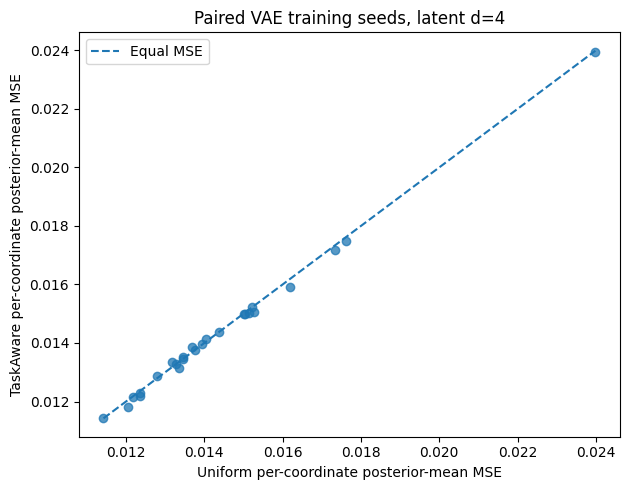

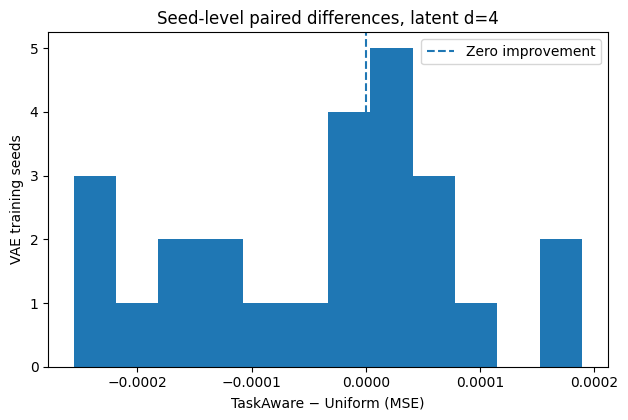

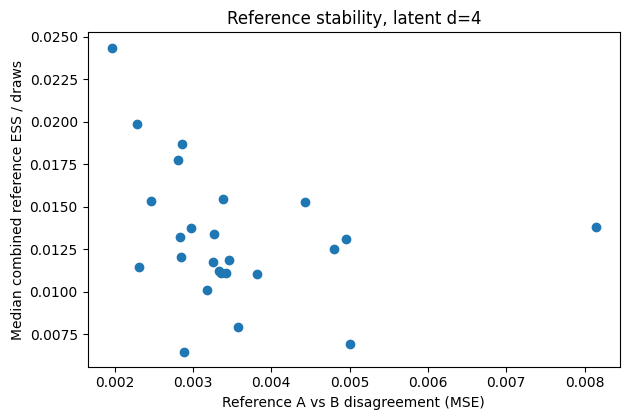

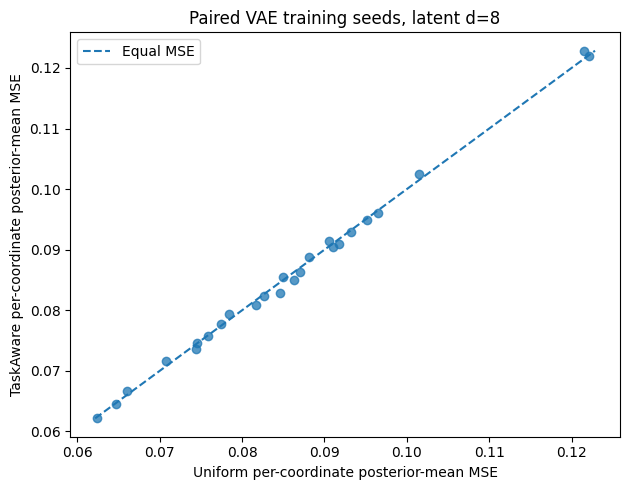

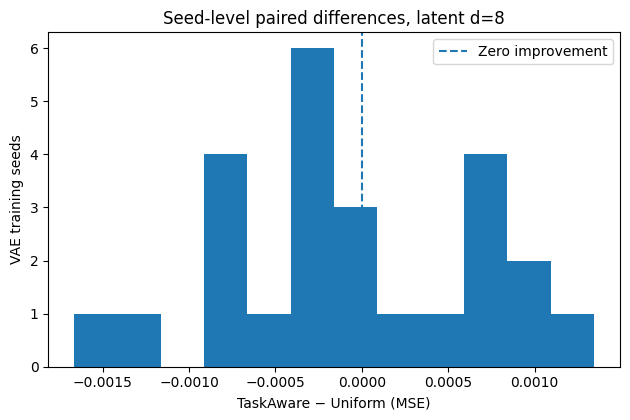

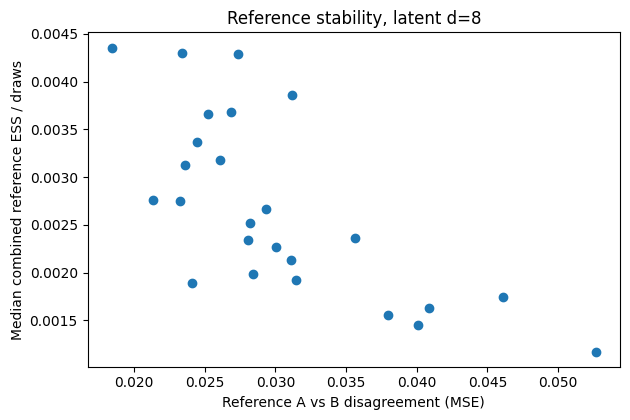

In [10]:
for dim in cfg.latent_dims:
    sd=seed_results[seed_results.latent_dim==dim]
    rd=reference_df[reference_df.latent_dim==dim]
    pivot=sd.pivot(index='seed',columns='method',values='mse')
    fig,ax=plt.subplots(figsize=(6.4,5))
    ax.scatter(pivot['Uniform'],pivot['TaskAware'],alpha=.75)
    lo=float(min(pivot[['Uniform','TaskAware']].min()))
    hi=float(max(pivot[['Uniform','TaskAware']].max()))
    ax.plot([lo,hi],[lo,hi],linestyle='--',label='Equal MSE')
    ax.set(xlabel='Uniform per-coordinate posterior-mean MSE',
           ylabel='TaskAware per-coordinate posterior-mean MSE',
           title=f'Paired VAE training seeds, latent d={dim}')
    ax.legend();fig.tight_layout()
    fig.savefig(OUT/f'd{dim}_paired_scatter.png',dpi=175)
    plt.show();plt.close(fig)

    fig,ax=plt.subplots(figsize=(6.4,4.3))
    vals=(pivot['TaskAware']-pivot['Uniform']).to_numpy()
    ax.hist(vals,bins=min(12,max(3,len(vals)//2)))
    ax.axvline(0,linestyle='--',label='Zero improvement')
    ax.set(xlabel='TaskAware − Uniform (MSE)',ylabel='VAE training seeds',
           title=f'Seed-level paired differences, latent d={dim}')
    ax.legend();fig.tight_layout()
    fig.savefig(OUT/f'd{dim}_paired_differences.png',dpi=175)
    plt.show();plt.close(fig)

    fig,ax=plt.subplots(figsize=(6.4,4.3))
    ax.scatter(rd['reference_pair_mse'],rd['reference_ess_fraction_median'])
    ax.set(xlabel='Reference A vs B disagreement (MSE)',
           ylabel='Median combined reference ESS / draws',
           title=f'Reference stability, latent d={dim}')
    fig.tight_layout()
    fig.savefig(OUT/f'd{dim}_reference_checks.png',dpi=175)
    plt.show();plt.close(fig)

## 11 · Automated SOP wording **with uncertainty safeguards**

This cell produces a cautious summary grounded in the experiment. It does **not** say a result is confirmed simply because the observed percentage is positive. It always mentions the actual fixed dataset, seed count, sampling budget, and reference limitations. Before putting the sentence in an SOP, check whether the method follows the same claim you want to make and whether the reference checks support the interpretation.

In [11]:
if RUN_MODE == 'smoke':
    print('SMOKE TEST: no SOP evidence note is generated. Re-run with RUN_MODE=\"full\".')
else:
    print('FULL RESEARCH RUN: inspect reference quality and uncertainty before using any sentence.')
row=primary.iloc[0]
ref=reference_df[reference_df.latent_dim==4]
ref_pair=float(ref.reference_pair_mse.mean())
abs_gap=abs(float(row.mean_paired_difference))
frac_ess=float(ref.reference_ess_fraction_below_1pct.mean())
supported=(row.mean_paired_difference<0 and row.paired_ci_high<0 and row.paired_signflip_p<0.05)
reference_caution=(ref_pair>=max(abs_gap,1e-12)*0.25 or frac_ess>0.10)

intro=(f'Across {int(row.n_seeds)} independently trained four-dimensional VAEs on a fixed '
       f'held-out set of 8×8 handwritten-digit images, a task-aware allocator showed '
       f'a {row.percent_reduction:.1f}% reduction in posterior-mean MSE relative to '
       f'uniform allocation at an average online budget of {cfg.k_average} samples per image '
       f'and an offline teacher budget of {cfg.k_teacher} samples per development observation.')
if supported and not reference_caution:
    verdict=('The paired training-seed analysis supported lower MSE '
             f'(95% CI for the difference: [{row.paired_ci_low:.5f}, '
             f'{row.paired_ci_high:.5f}]; sign-flip p={row.paired_signflip_p:.4g}).')
elif supported:
    verdict=('The paired seed-level comparison favored task-aware allocation, but independent '
             'high-budget reference checks raise uncertainty about the precision of the '
             'measured effect; further reference refinement is warranted.')
else:
    verdict=('The paired seed-level analysis did not establish a reliable improvement, '
             'so the observed percentage should be described as preliminary.')
caveat=('These results use high-budget importance-sampling references, not exact posterior '
        'means, and are limited to one handwritten-digit split and VAE architecture.')
msg=intro+' '+verdict+' '+caveat
if RUN_MODE == 'full':
    print('\nSOP EVIDENCE NOTE — revise for style before submission:\n')
    print(msg)
    (OUT/'SOP_evidence_note.txt').write_text(msg+'\n')
else:
    print('Suppressed SOP note because this was a smoke test.')
print('\nPrimary summary CSV:',OUT/'paired_comparisons.csv')
print('All outputs saved under:',OUT.resolve())

FULL RESEARCH RUN: inspect reference quality and uncertainty before using any sentence.

SOP EVIDENCE NOTE — revise for style before submission:

Across 25 independently trained four-dimensional VAEs on a fixed held-out set of 8×8 handwritten-digit images, a task-aware allocator showed a 0.3% reduction in posterior-mean MSE relative to uniform allocation at an average online budget of 48 samples per image and an offline teacher budget of 512 samples per development observation. The paired seed-level analysis did not establish a reliable improvement, so the observed percentage should be described as preliminary. These results use high-budget importance-sampling references, not exact posterior means, and are limited to one handwritten-digit split and VAE architecture.

Primary summary CSV: /content/TaskAware_VAE_Confirmation/full_86f150f51f1b/paired_comparisons.csv
All outputs saved under: /content/TaskAware_VAE_Confirmation/full_86f150f51f1b


## 12 · Export all experimental artifacts

In Colab, this ZIP includes configuration, software/device versions, per-seed results, seed-level comparisons, diagnostics, plots, and evidence wording. If `USE_GOOGLE_DRIVE=False`, download this ZIP before ending the Colab session. These are **results from your execution**, not results supplied with this notebook.

In [12]:
import shutil
zip_target=shutil.make_archive(str(OUT), 'zip', root_dir=str(OUT))
print('ZIP created:',zip_target)
try:
    from google.colab import files
    print('To download the ZIP, run: files.download(zip_target)')
except ImportError:
    print('Colab download control is available only in Google Colab.')

ZIP created: /content/TaskAware_VAE_Confirmation/full_86f150f51f1b.zip
To download the ZIP, run: files.download(zip_target)


## Before describing this in an SOP

1. Run **full** mode all the way through. Do not use smoke-test results.
2. Check that 25/25 seeds completed, that every group has exactly 3,072 allocated samples, and that the separate reference pools agree sufficiently. If reference ESS is low or the two references disagree substantially, increase `n_reference_each`, **rerun the entire pre-specified evaluation**, and disclose the change rather than retrofitting a positive claim.
3. Read the paired seed-level confidence interval, permutation p-value, and reference diagnostics. Avoid calling a positive point estimate conclusive if the paired interval includes zero.
4. Say **8 × 8 digits**, **independently trained VAEs**, and **estimated posterior mean**; do not write “proven to generalize to generative models.”
5. This experiment evaluates *sample allocation*, not model security or decision boundaries. Keep any claimed connection to adversarial ML at the level of your evolving research interests, not as experimental proof of attack improvements.

**Optional extensions, separate from this pre-specified primary test:** compare an 8-dimensional latent VAE (`RUN_8D_SECONDARY=True`), multiple digit train/test splits, mixture proposals for low-ESS images, or predictive-calibration diagnostics. All are valuable but must be labeled additional experiments.